In [2]:
   pip install pandas matplotlib seaborn pingouin scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
   import pandas as pd
   nhanes = pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")
   children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]

/tmp/ipykernel_11554/683564764.py:2: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes = pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")


<Axes: >

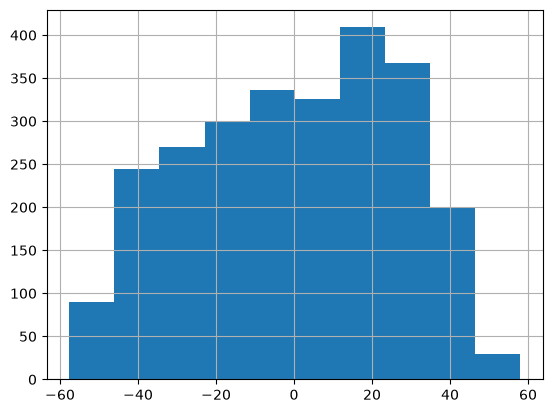

In [6]:
#Q2 (a)line1 
(children["StandingHeightCm"] - children["StandingHeightCm"].mean()).hist()

<Axes: >

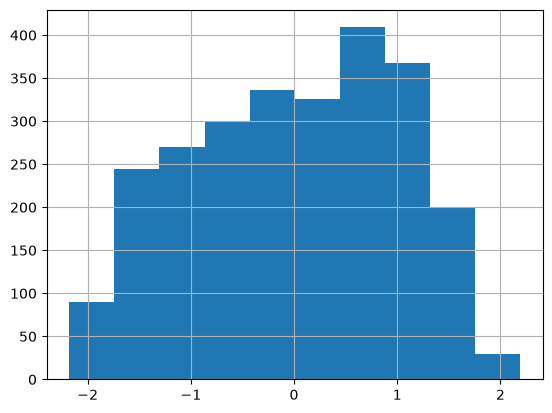

In [9]:
#Q2 (a) line 2
((children["StandingHeightCm"] - children["StandingHeightCm"].mean())/children["StandingHeightCm"].std()).hist()

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

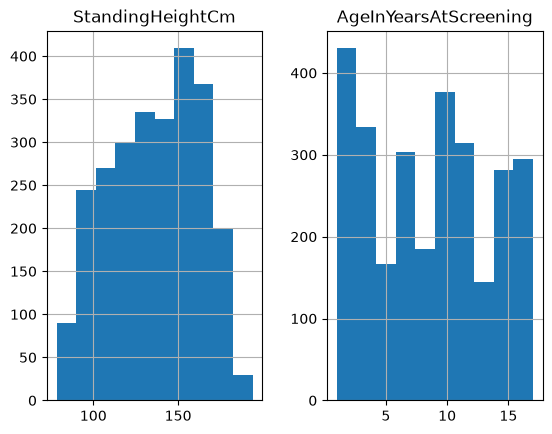

In [11]:
#(b) line 1
children[["StandingHeightCm","AgeInYearsAtScreening"]].hist()

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

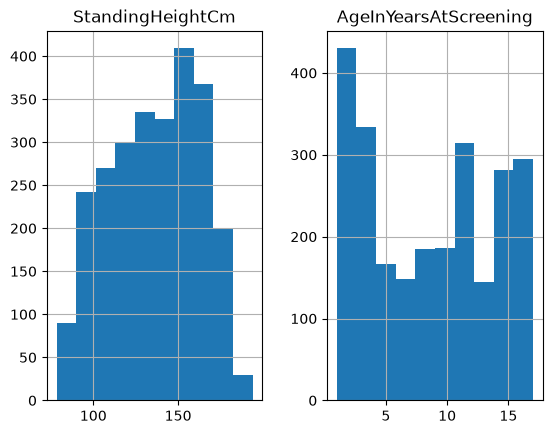

In [12]:
# (b) line 2
children[["StandingHeightCm","AgeInYearsAtScreening"]].replace([7,9,77,99,777,999,7777,9999], pd.NA).astype("Float64").hist()

In [13]:
# (c) line 1
children["AgeInYearsAtScreening"].describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [14]:
# (c)line 2
children["AgeInYearsAtScreening"].dropna().describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [16]:
# (d) without line
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)

,names,coef,se,T,pval,r2,adj_r2,CI2.5,CI97.5
0,Intercept,-2.443957,0.568574,-4.298396,0.000017,0.249317,0.249223,-3.558511,-1.329404
1,StandingHeightCm,0.185338,0.003595,51.555402,0.000000,0.249317,0.249223,0.178291,0.192385


<Axes: xlabel='StandingHeightCm', ylabel='BodyMassIndexKgm2'>

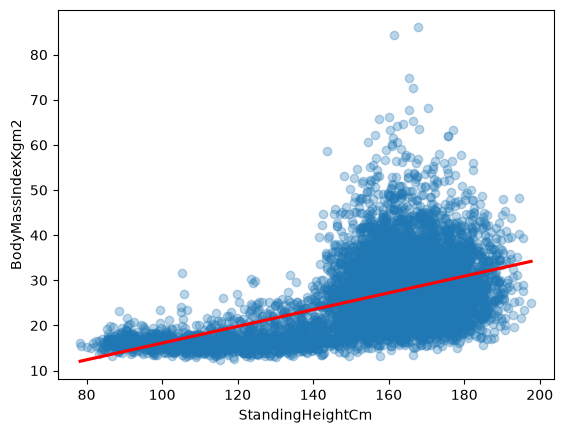

In [17]:
# (d) with line
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)
sns.regplot(data=nhanes,x="StandingHeightCm", y="BodyMassIndexKgm2",scatter_kws={"color": "C0", "alpha": 0.3},line_kws={"color": "red"})

/tmp/ipykernel_11554/3442450490.py:4: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes = pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")
/tmp/ipykernel_11554/3442450490.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)


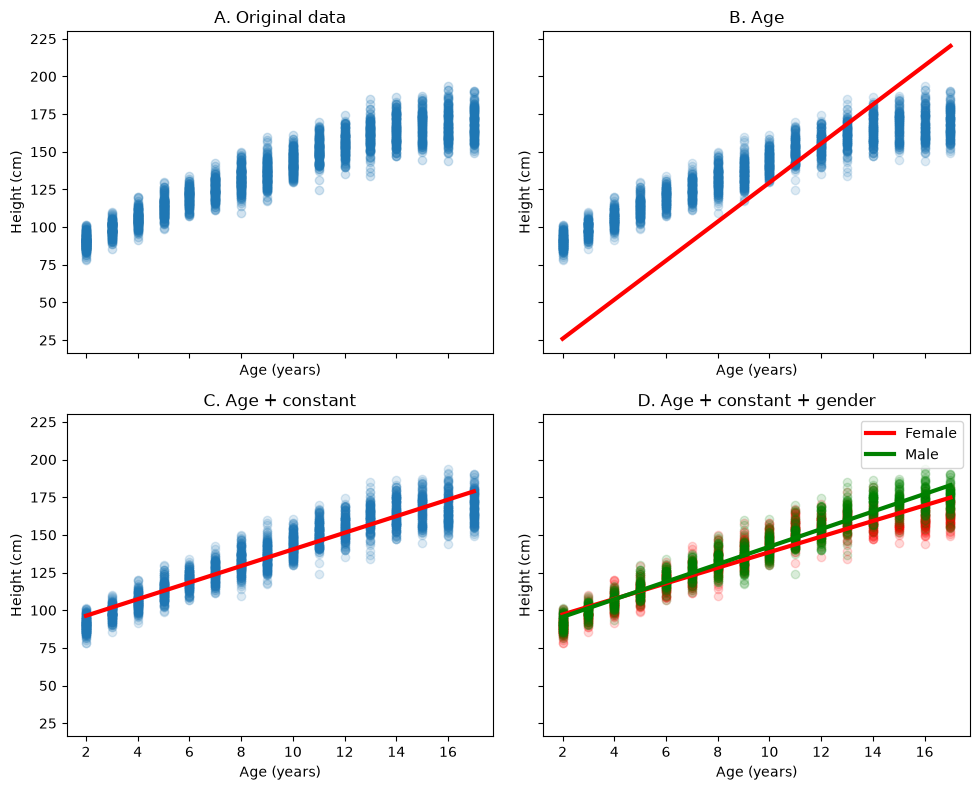

In [ ]:
#Q3
# code from:https://github.com/Psyc3000A/Data/blob/main/Code/class3.ipynb

import pandas as pd
nhanes = pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")
children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]

import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)
children  = children[["StandingHeightCm", "AgeInYearsAtScreening", "Gender_code"]].dropna()

m_age = LinearRegression(fit_intercept=False).fit(children[["AgeInYearsAtScreening"]],children["StandingHeightCm"])
m_age_const = LinearRegression().fit(children[["AgeInYearsAtScreening"]], children["StandingHeightCm"])

m_full = LinearRegression().fit(children[["AgeInYearsAtScreening", "Gender_code"]],children["StandingHeightCm"])
children = children.sort_values("AgeInYearsAtScreening")

children["pred_age"] = m_age.predict(children[["AgeInYearsAtScreening"]])
children["pred_age_const"] = m_age_const.predict(children[["AgeInYearsAtScreening"]])
children["pred_full"] = m_full.predict(children[["AgeInYearsAtScreening", "Gender_code"]])

children["Age_Gender"] = (children["AgeInYearsAtScreening"] * children["Gender_code"])

m_interaction = LinearRegression().fit(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]],children["StandingHeightCm"])

children["pred_interaction"] = m_interaction.predict(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]])
fig, ax = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)

# A: Original data
ax[0,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.2)
ax[0,0].set_title("A. Original data")

# B: Age only
ax[0,1].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[0,1].plot(children["AgeInYearsAtScreening"], children["pred_age"], color="red", lw=3)
ax[0,1].set_title("B. Age")

# C: Age + constant
ax[1,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[1,0].plot(children["AgeInYearsAtScreening"], children["pred_age_const"], color="red", lw=3)
ax[1,0].set_title("C. Age + constant")

# D: Age + constant + gender
for g, color, label in [(0, "red", "Female"),(1, "green", "Male")]:
    tmp = children[children["Gender_code"] == g].sort_values("AgeInYearsAtScreening")
    ax[1,1].scatter(tmp["AgeInYearsAtScreening"],tmp["StandingHeightCm"],alpha=.15,color=color)
    ax[1,1].plot(tmp["AgeInYearsAtScreening"],tmp["pred_interaction"],color=color,lw=3,label=label)
ax[1,1].legend()
ax[1,1].set_title("D. Age + constant + gender")

for a in ax.ravel():
    a.set_xlabel("Age (years)")
    a.set_ylabel("Height (cm)")
plt.tight_layout()
plt.show()